In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

data = pd.read_csv('lab1.csv')



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.12/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 701, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.12/site-

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



ImportError: initialization failed

In [ ]:
m = data.shape[0] # total number of rows from the dataset
x = np.hstack((np.ones((m,1)), data.Hours.values.reshape(-1,1))) # takes x values and transforms them into a mx2 matrix, creates a vertical col of 1's, preserves bias
y = np.array(data['Scores']).reshape(-1,1) # transposes the y col 
theta = np.zeros(shape=(x.shape[1],1)) # creates a weight array by col_size of x for rows and 1 col

num_iters = 2500
lr = 0.01

NameError: name 'data' is not defined

In [ ]:
def compute_cost(x,y,theta):
    n = y.shape[0] # total number of rows in y matrix
    h = x.dot(theta) # takes the dot product of x and theta
    j = (1/(2*n))*(np.sum((h-y)**2)) # takes the MSE
    return j

In [ ]:
j = compute_cost(x,y,theta) # computes the total lousiness of the model
print('With theta = [0;0]\nCost computed = ',j)

With theta = [0;0]
Cost computed =  1936.6068376068379


In [ ]:
def gradient_descent(x,y,theta,lr,num_iters):
    s = y.shape[0] # total rows of y
    j = np.zeros(shape=(num_iters,1)) # creates a empty array of size iters to store cost

    for i in range(0, num_iters):
        h = x.dot(theta) # takes the dot product if x and theta
        diff = h-y # takes the difference between the expected output and the correct output

        delta = (1/s)*(diff.T.dot(x)) # calculates direction in which to move weights to reduce error
        theta = theta - (lr * delta.T) # updates weights
        j[i] = compute_cost(x,y,theta) # logs cost at each interval

    return theta, j

In [ ]:
def predict(hours, theta):

    hours = np.array(hours).reshape(-1, 1)

    # Add bias column
    X_new = np.hstack((np.ones((hours.shape[0], 1)), hours))

    predictions = X_new.dot(theta)

    return predictions

In [ ]:
theta, _ = gradient_descent(x, y, theta, lr, num_iters) # train the model

print('Theta found by gradient descent:',theta)

Theta found by gradient descent: [[3.10226545]
 [9.70823624]]


In [ ]:
hours = 6.5

prediction = predict(hours, theta)

print(f"If a student studies {hours} hours,")
print(f"Predicted score: {prediction[0][0]:.2f}")

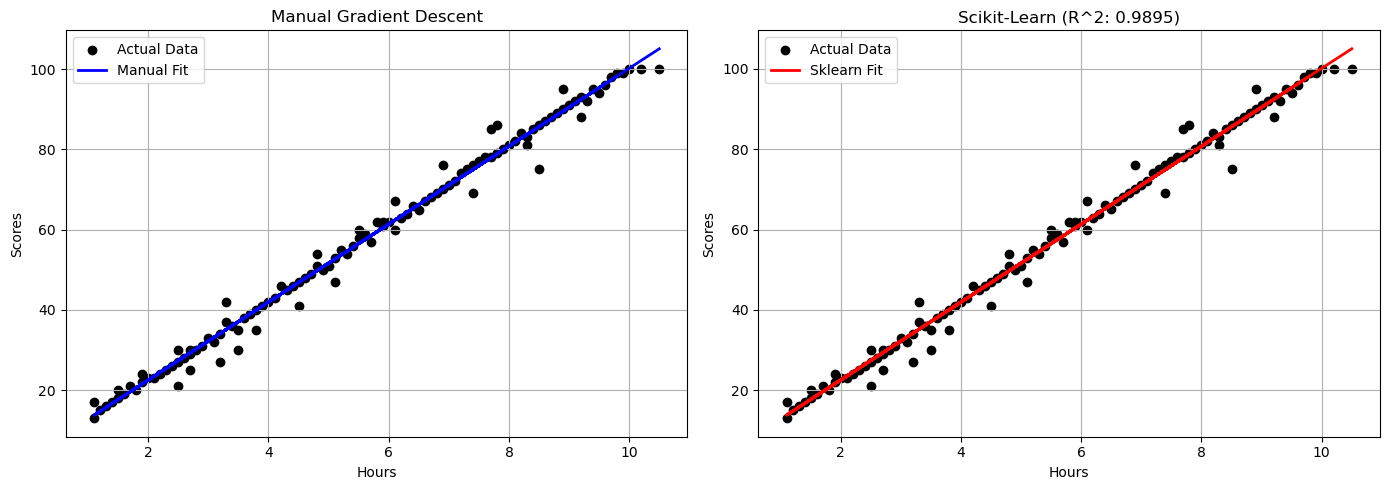


--- SCIKIT-LEARN RESULTS ---
Slope (Coefficient): 9.7057
Intercept (Bias):    3.1196
Accuracy (R^2 Score): 0.9895

Theta found by gradient descent: [[3.10226545]
 [9.70823624]]


In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(data['Hours'], data['Scores'], color='black', label='Actual Data')
ax1.plot(x[:, 1], x.dot(theta), color='blue', linewidth=2, label='Manual Fit')
ax1.set_title("Manual Gradient Descent")
ax1.set_xlabel("Hours")
ax1.set_ylabel("Scores")
ax1.grid(True)
ax1.legend()

model = LinearRegression()
model.fit(x, y)
accuracy = model.score(x, y)

ax2.scatter(data['Hours'], data['Scores'], color='black', label='Actual Data')
ax2.plot(x[:, 1], model.predict(x), color='red', linewidth=2, label='Sklearn Fit')
ax2.set_title(f"Scikit-Learn (R^2: {accuracy:.4f})")
ax2.set_xlabel("Hours")
ax2.set_ylabel("Scores")
ax2.grid(True)
ax2.legend()

plt.tight_layout() 
plt.show()

slope = model.coef_[0][1] 
intercept = model.intercept_[0]
print("\n--- SCIKIT-LEARN RESULTS ---")
print(f"Slope (Coefficient): {slope:.4f}")
print(f"Intercept (Bias):    {intercept:.4f}")
print(f"Accuracy (R^2 Score): {accuracy:.4f}")
print('\nTheta found by gradient descent:',theta)